# Üç Başlangıçlı Ana Deneyler

Bu defter tam eğitim ve doğrulama verisiyle yürütülen promptsuz uyarlama, KPT ve KMPT deneylerinin bağımsız test sonuçlarını inceler. Dokuz koşul tamamlanmadan sonuç analizi çalıştırılmaz. Defter model eğitimi başlatmaz ve test sonuçlarına göre ayar değiştirmez.

**Tarihsel sürüm kaydı.** Bu defter ilk uygulamanın çıktısını korur. Yöntem denetimi ve düzeltilmiş ana sonuçlar 08_Makale_Yontem_Denetimi_ve_Duzeltilmis_Deneyler.ipynb içindedir. Öğrenci takibi için 05–07 defterleri güncel ağırlıklarla yeniden çalıştırılmıştır.

In [1]:
from pathlib import Path
import json
import sys
import inspect
import subprocess
import pandas as pd
from IPython.display import display, Image, Markdown, Code

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "kt_project").exists():
    ROOT = ROOT.parent
assert (ROOT / "src" / "kt_project").exists()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
RUN = ROOT / "outputs" / "main" / "three_seed_v1"
status = json.loads((RUN / "status.json").read_text(encoding="utf-8"))
assert status["status"] == "complete", "Ana deneylerin tamamlanması gerekiyor."

## Sonuçları ham tahminlerden denetleme

Analiz, üç yöntem ve üç başlangıcın eksiksiz olduğunu kontrol eder. Bütün koşulların aynı test hedeflerini kullandığı ve kaydedilmiş tahminlerin gerçek etiketlerle eşleştiği doğrulanır. AUC, doğruluk ve BCE değerleri kaydedilmiş olasılıklardan yeniden hesaplanır.

In [2]:
analyzed = subprocess.run([sys.executable, str(ROOT / "scripts" / "analyze_main.py")],
                          cwd=ROOT, capture_output=True, text=True, encoding="utf-8", check=True)
results = json.loads((RUN / "results.json").read_text(encoding="utf-8"))
summary = json.loads((RUN / "analysis" / "summary.json").read_text(encoding="utf-8"))
integrity = json.loads((RUN / "analysis" / "integrity.json").read_text(encoding="utf-8"))
assert integrity["all_checks_passed"] and integrity["complete_method_seed_pairs"] == 9
display(pd.DataFrame([{
    "Tamamlanan karşılaştırma": integrity["complete_method_seed_pairs"],
    "Test öğrencisi": integrity["test_students"],
    "Ortak test hedefi": integrity["test_targets"],
    "Eğitimde görülmeyen soru hedefi": integrity["unseen_question_test_targets"],
    "Kaynak içerik özetleri doğrulandı": integrity["implementation_hashes_verified"],
}]))

,Tamamlanan karşılaştırma,Test öğrencisi,Ortak test hedefi,Eğitimde görülmeyen soru hedefi,Kaynak içerik özetleri doğrulandı
0,9,548,44791,304,True


## Gerçek deney ayarları

Ayarlar her koşul için aynı kalır. Her başlangıç içinde LKM bir kez ön eğitilir ve üç yönteme kopyalanır. Öğrenci ayrımı başlangıçlar arasında değişmez. Testte her öğrencinin ilk etkileşimi geçmiş başlangıcı olarak kullanılır; diğer cevaplar birer tahmin hedefidir.

In [3]:
settings = json.loads((RUN / "config.json").read_text(encoding="utf-8"))
display(pd.DataFrame([{
    "Başlangıçlar": str(settings["seeds"]),
    "Gizli boyut": settings["model"]["hidden_size"],
    "LKM katmanı": settings["model"]["layers"],
    "En uzun geçmiş": settings["model"]["max_history"],
    "Toplu örnek sayısı": settings["batch_size"],
    "Ön eğitim dönemi": settings["pretraining_epochs"],
    "En fazla uyarlama dönemi": settings["finetuning_epochs"],
    "Erken durdurma sabrı": settings["patience"],
    "Hassasiyet": results["precision"],
}]))
for seed in settings["seeds"]:
    assert len({row["initial_lkm_sha256"] for row in results["runs"] if row["seed"] == seed}) == 1
print("Her başlangıçta üç yöntemin LKM başlangıcı aynı.")

,Başlangıçlar,Gizli boyut,LKM katmanı,En uzun geçmiş,Toplu örnek sayısı,Ön eğitim dönemi,En fazla uyarlama dönemi,Erken durdurma sabrı,Hassasiyet
0,"[17, 42, 2026]",128,2,128,512,10,15,4,bfloat16


Her başlangıçta üç yöntemin LKM başlangıcı aynı.


## Üç başlangıcın ortalaması ve değişkenliği

Standart sapma üç bağımsız başlangıç üzerinden, örnek standart sapması olarak hesaplanır. Bu değer aynı öğrenci ayrımındaki optimizasyon değişkenliğidir; öğrenci evreninin güven aralığı değildir. Ölçüler etkileşim ağırlıklıdır.

,Yöntem,Test AUC ortalama ± SS,Test doğruluğu yüzde ortalama ± SS,Test BCE ortalama ± SS
0,Promptsuz uyarlama,0.7672 ± 0.0029,73.27 ± 0.26,0.5461 ± 0.0036
1,KPT,0.7586 ± 0.0023,72.57 ± 0.39,0.5506 ± 0.0030
2,KMPT,0.7558 ± 0.0025,72.37 ± 0.22,0.5632 ± 0.0040


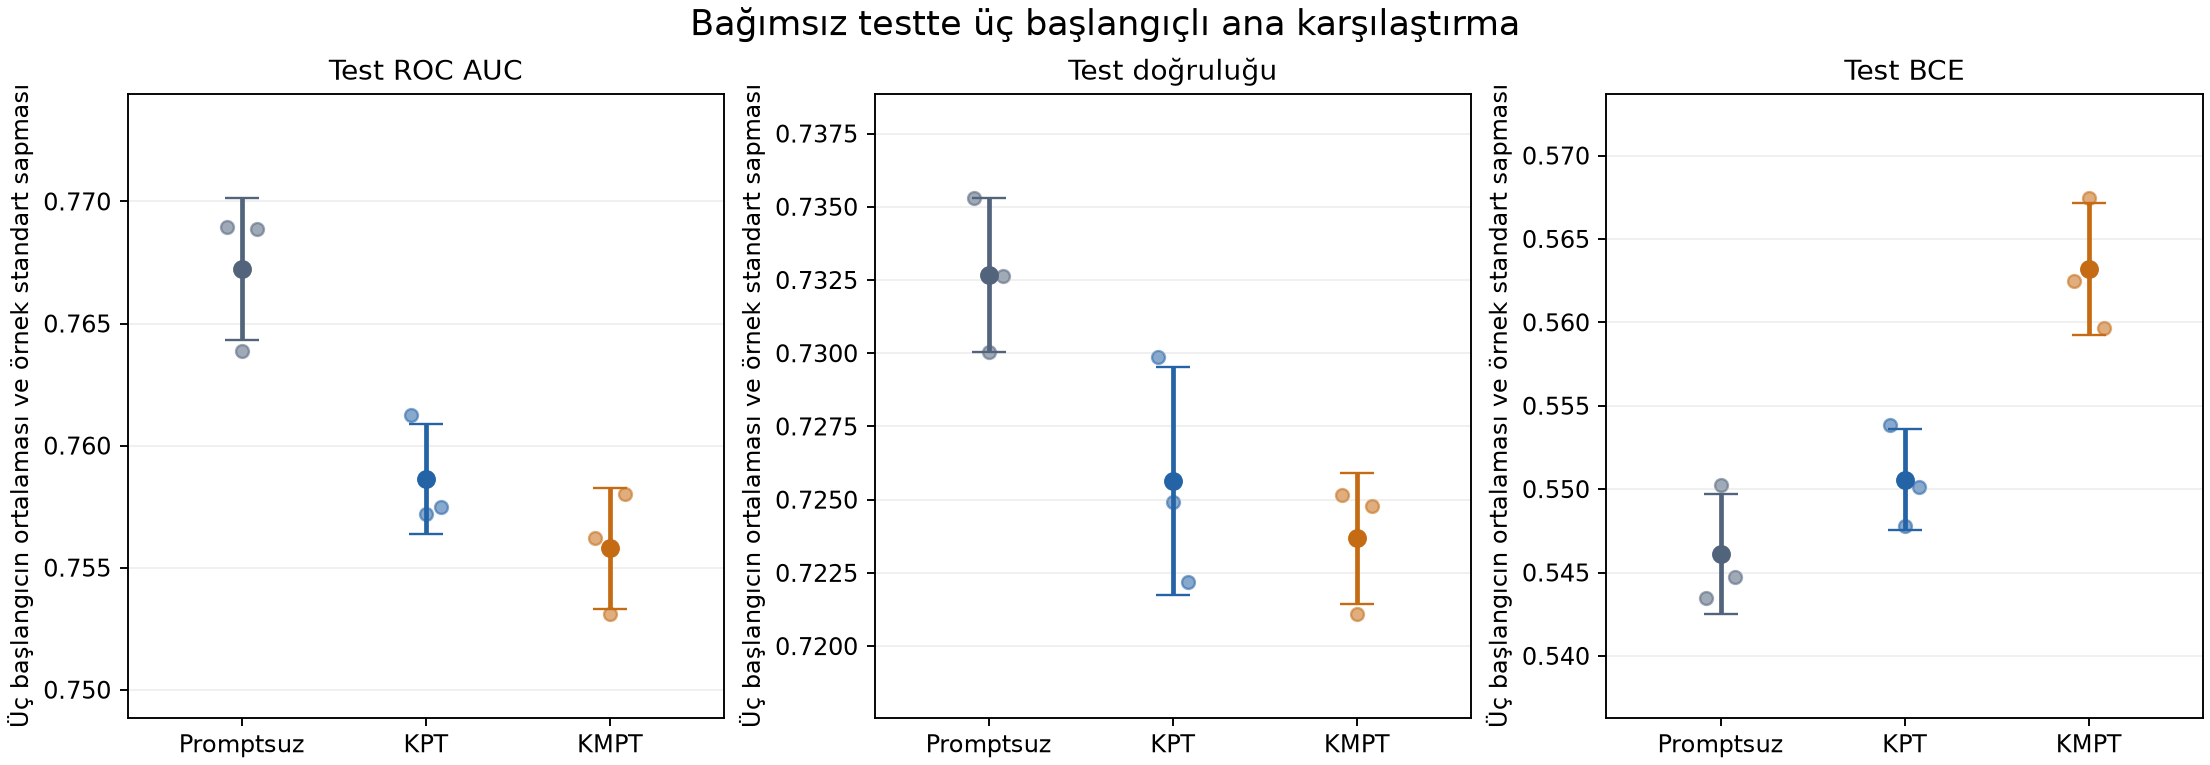

In [4]:
names = {"baseline": "Promptsuz uyarlama", "kpt": "KPT", "kmpt": "KMPT"}
rows = []
for method in ("baseline", "kpt", "kmpt"):
    metrics = summary[method]["test"]
    rows.append({
        "Yöntem": names[method],
        "Test AUC ortalama ± SS": f"{metrics['auc']['mean']:.4f} ± {metrics['auc']['sample_sd']:.4f}",
        "Test doğruluğu yüzde ortalama ± SS": f"{100*metrics['accuracy']['mean']:.2f} ± {100*metrics['accuracy']['sample_sd']:.2f}",
        "Test BCE ortalama ± SS": f"{metrics['bce']['mean']:.4f} ± {metrics['bce']['sample_sd']:.4f}",
    })
display(pd.DataFrame(rows))
display(Image(filename=str(ROOT / "outputs" / "figures" / "main_test_comparison.png")))

## Ortalamanın nasıl hesaplandığı

Ana tablo eksik koşullardan üretilemez. Aynı başlangıçtaki yöntem farkları ayrıca hesaplanır. Üç ölçü için farklı dönemler seçilmez; doğrulama BCE ile seçilen dönem bütün ölçülerde kullanılır.

In [5]:
from kt_project.experiment_results import aggregate_runs
display(Code(inspect.getsource(aggregate_runs), language="python"))

def aggregate_runs(runs):
    expected = {(method, seed) for method in METHODS for seed in SEEDS}
    observed = [(row["method"], row["seed"]) for row in runs]
    if len(observed) != len(expected) or set(observed) != expected:
        raise ValueError("Ana karşılaştırma her yöntem ve başlangıç için tam bir sonuç gerektirir.")
    summaries = {}
    baseline = {row["seed"]: row for row in runs if row["method"] == "baseline"}
    for method in METHODS:
        selected = [row for row in runs if row["method"] == method]
        if any(row.get("test") is None for row in selected):
            raise ValueError("Ana karşılaştırmada test sonucu eksik.")
        scores = {}
        for metric in ("auc", "accuracy", "bce"):
            values = np.array([row["test"][metric] for row in selected], dtype=float)
            if not np.isfinite(values).all():
                raise ValueError("Ana ölçüler sonlu olmalı.")
            scores[metric] = {"mean": float(values.mean()), "sample_sd": float(values.std(ddof=1))}
        differences = np.array([row["test"]["auc"] - baseline[row["seed"]]["test"]["auc"]
                                for row in selected])
        summaries[method] = {
            "seeds": len(selected), "test": scores,
            "auc_difference_from_baseline": {"mean": float(differences.mean()),
                                               "sample_sd": float(differences.std(ddof=1))},
            "mean_training_seconds": float(np.mean([row["training_seconds"] for row in selected])),
        }
    return summaries

## Her başlangıcın ayrı sonucu

Tek bir iyi koşulu seçmek yerine bütün koşullar gösterilir. Dönem seçiminde bağımsız test ölçüleri kullanılmaz.

,Başlangıç,Yöntem,Seçilen dönem,Doğrulama BCE,Test AUC,Test BCE,Test doğruluğu
0,17,Promptsuz uyarlama,1,0.5501,0.7690,0.5434,0.7353
1,17,KPT,1,0.5636,0.7612,0.5538,0.7299
2,17,KMPT,1,0.5715,0.7562,0.5625,0.7251
3,42,Promptsuz uyarlama,1,0.5562,0.7639,0.5502,0.7300
4,42,KPT,1,0.5540,0.7572,0.5478,0.7249
5,42,KMPT,2,0.5745,0.7531,0.5675,0.7211
6,2026,Promptsuz uyarlama,1,0.5522,0.7689,0.5447,0.7326
7,2026,KPT,1,0.5581,0.7575,0.5501,0.7222
8,2026,KMPT,2,0.5660,0.7580,0.5597,0.7248


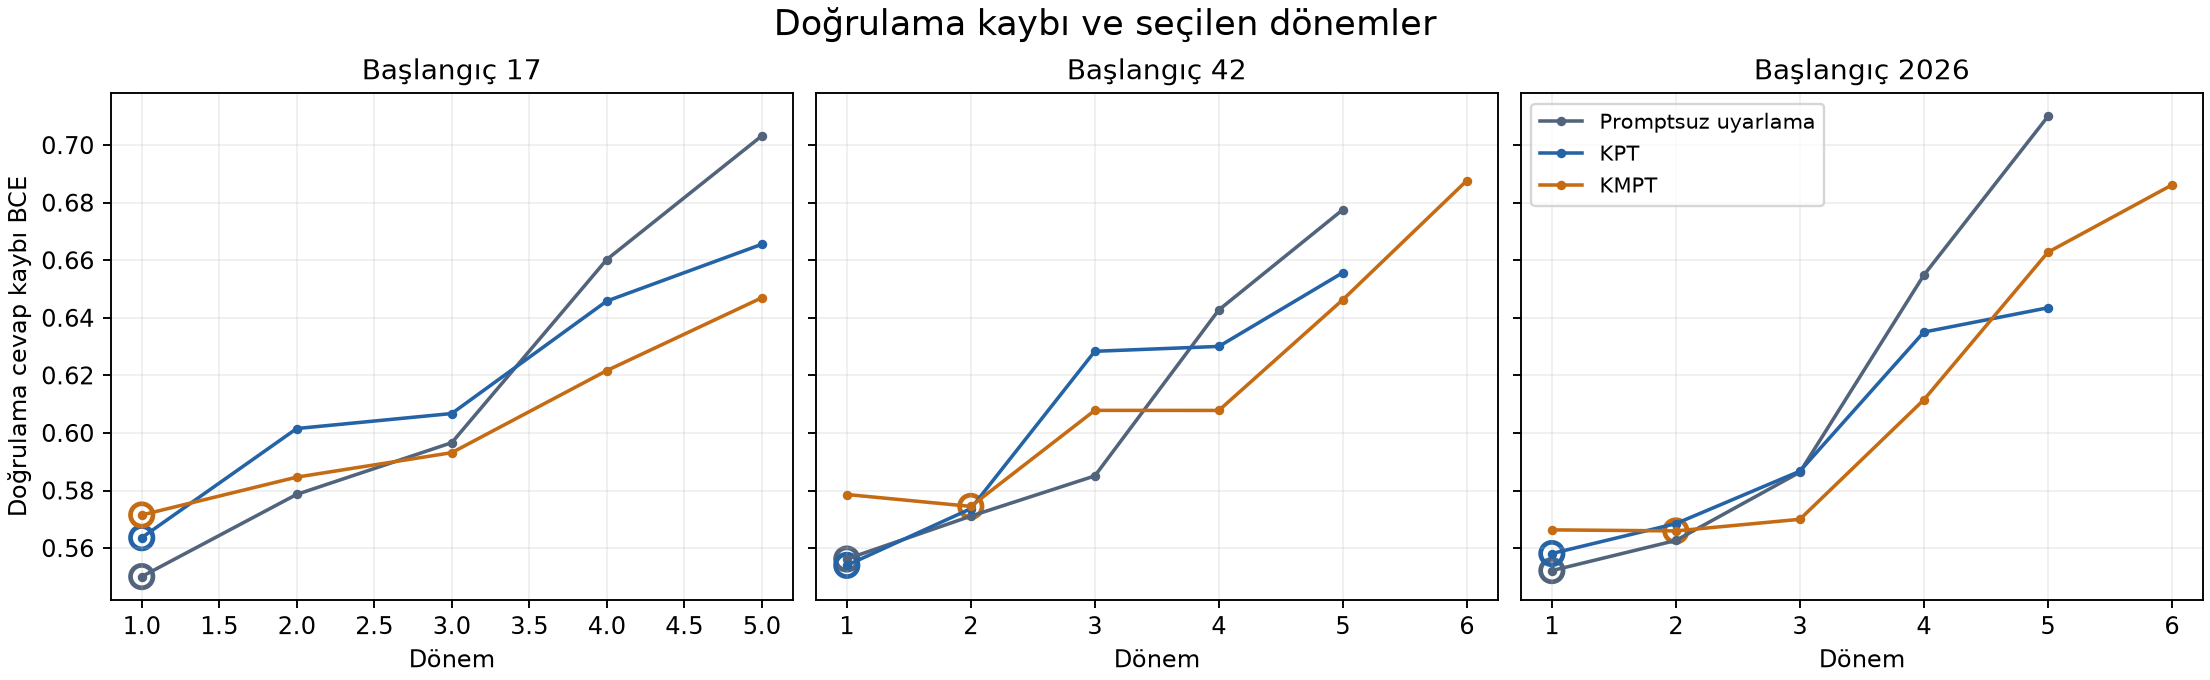

In [6]:
display(pd.DataFrame([{
    "Başlangıç": row["seed"], "Yöntem": names[row["method"]],
    "Seçilen dönem": row["best_epoch"],
    "Doğrulama BCE": row["validation"]["bce"],
    "Test AUC": row["test"]["auc"], "Test BCE": row["test"]["bce"],
    "Test doğruluğu": row["test"]["accuracy"],
} for row in results["runs"]]).round(4))
display(Image(filename=str(ROOT / "outputs" / "figures" / "main_validation_curves.png")))

## Test ROC eğrileri

Her yöntemin üç başlangıcı aynı test hedeflerinde değerlendirilir. Eğriler, bu koşullarda eşik değiştikçe doğru ve yanlış pozitif oranlarının nasıl değiştiğini gösterir.

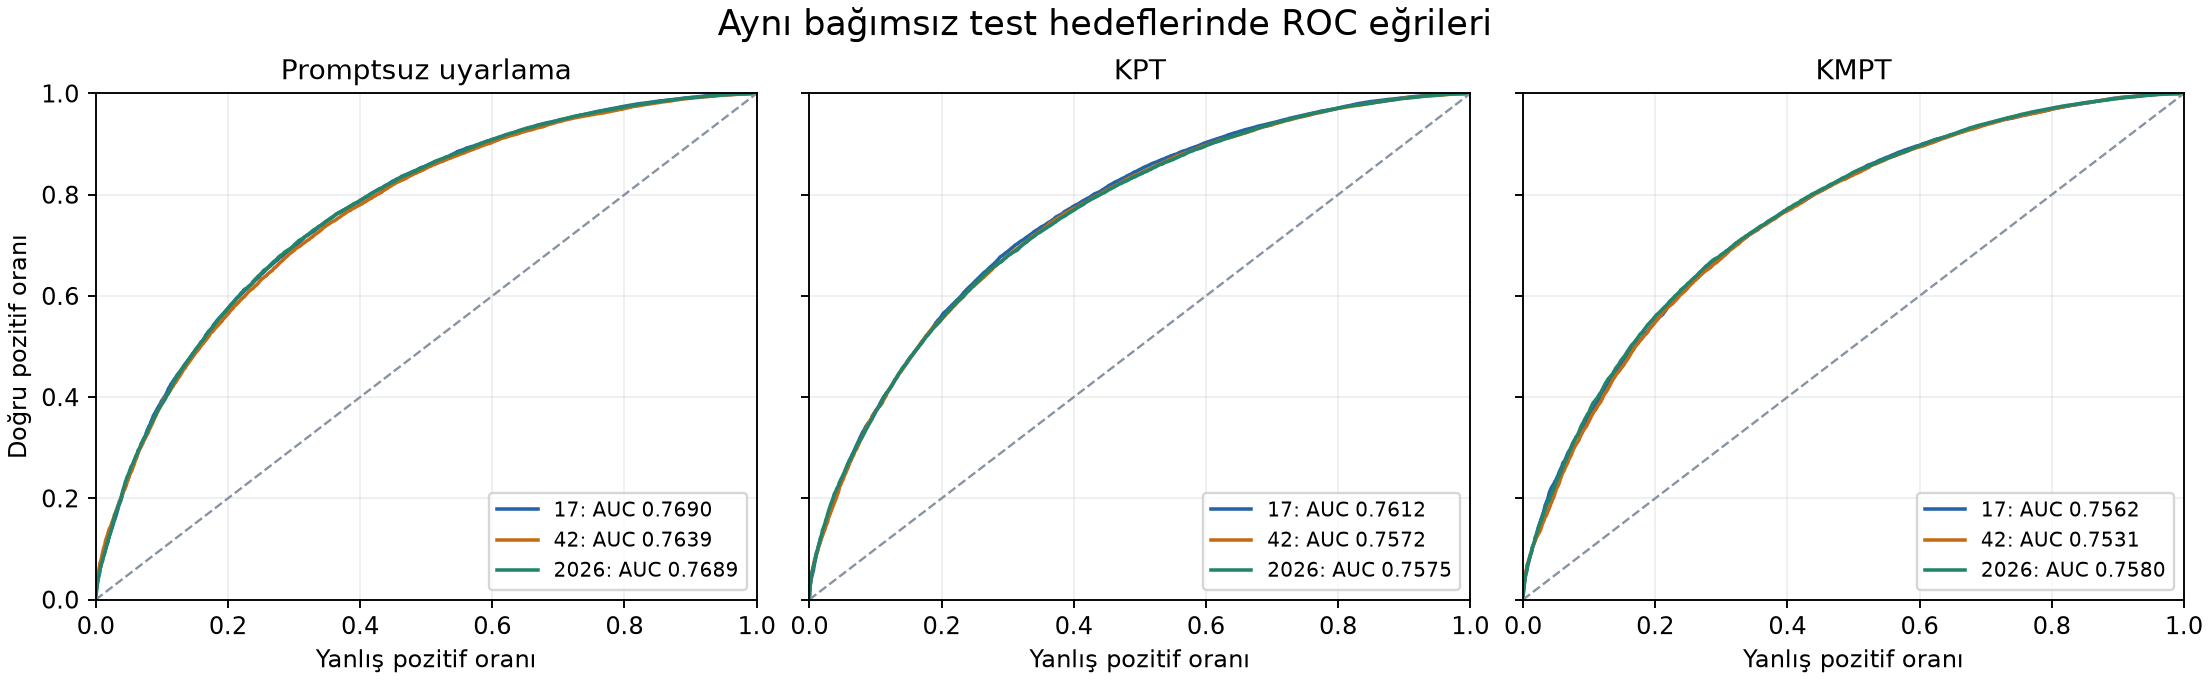

In [7]:
display(Image(filename=str(ROOT / "outputs" / "figures" / "main_roc_curves.png")))

## Örnek oturum modelinin seçimi

Örnek oturum için yöntem önceden KMPT olarak belirlenmiştir. Kullanılacak başlangıç, KMPT'nin üç doğrulama BCE değeri arasından seçilir. Bu seçim, hangi yöntemin testte daha iyi olduğuna ilişkin karşılaştırmadan ayrıdır.

In [8]:
selection = json.loads((RUN / "analysis" / "prototype_selection.json").read_text(encoding="utf-8"))
assert selection["test_metrics_used_for_selection"] is False
display(pd.DataFrame([selection]))

,method,seed,criterion,validation_bce,best_epoch,test_metrics_used_for_selection,checkpoint
0,kmpt,2026,minimum validation BCE within the preselected ...,0.565962,2,False,outputs/main/three_seed_v1/seed_2026/kmpt_best.pt


## Projenin otomatik güvenilirlik kontrolleri

Veri ayrımı, modelin bilgi sınırı, çalışma defteri başlatıcısı ve sonuç analizinin kontrolleri birlikte çalıştırılır. Bu kontroller modelleri yeniden eğitmez ve bağımsız test sonuçlarına göre ayar değiştirmez.

In [9]:
checked = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
                         cwd=ROOT, capture_output=True, text=True, encoding="utf-8")
transcript = checked.stdout + checked.stderr
print(transcript)
assert checked.returncode == 0, "Otomatik güvenilirlik kontrolü başarısız."
(ROOT / "outputs" / "validation" / "main_test_output.txt").write_text(transcript, encoding="utf-8")

test_multiple_skills_are_one_event_and_conflicts_are_excluded (test_data_preparation.PreparationTests.test_multiple_skills_are_one_event_and_conflicts_are_excluded) ... ok
test_test_answers_do_not_change_training_difficulty_or_references (test_data_preparation.PreparationTests.test_test_answers_do_not_change_training_difficulty_or_references) ... ok
test_missing_or_duplicated_run_is_rejected (test_experiment_results.ExperimentResultsTests.test_missing_or_duplicated_run_is_rejected) ... ok
test_prototype_selection_is_unchanged_when_test_scores_change (test_experiment_results.ExperimentResultsTests.test_prototype_selection_is_unchanged_when_test_scores_change) ... ok
test_sample_standard_deviation_uses_three_independent_seeds (test_experiment_results.ExperimentResultsTests.test_sample_standard_deviation_uses_three_independent_seeds) ... ok
test_complete_fixture_is_verified (test_experiment_results.SavedExperimentAuditTests.test_complete_fixture_is_verified) ... ok
test_nonfinite_saved_we

3191

## Sonuçların yorumu ve uygulamanın sınırları

Bu karşılaştırma model uyarlama yöntemlerinin toplam etkisini ölçer. Saf PEFT deneyi veya yalnızca soft promptlara ait bir ablasyon değildir. Model kapasitesi ve veri işleme ayrıntıları makalenin birebir tekrarından farklıdır.

In [10]:
display(Markdown((ROOT / "docs" / "ana_deney_sonuclari.md").read_text(encoding="utf-8")))

# Üç Başlangıçlı Ana Deney Sonuçları

Promptsuz uyarlama, KPT ve KMPT; aynı öğrenci ayrımında, her başlangıç için ortak LKM ağırlıklarından başlayarak karşılaştırıldı. En iyi dönem yalnızca doğrulama BCE değerinden seçildi. Seçilen ağırlıklar bağımsız testte değerlendirildi.

## Veri ve deney düzeni

Her koşul 194663 eğitim ve 38792 doğrulama hedefi kullandı. Testte 548 öğrenciye ait 44791 cevap hedefi bulunuyor. Her öğrencinin ilk etkileşimi başlangıç geçmişi olarak kullanıldığı için hedef sayıları ham etkileşim sayılarından daha düşüktür.

Başlangıçlar 17, 42 ve 2026. Aynı başlangıç içindeki üç yöntemin LKM içerik özetleri eşleşiyor. Farklı başlangıçların LKM özetleri farklı. Veri hazırlama ve model kaynaklarının eğitim anındaki içerik özetleri doğrulandı.

## Birincil test sonuçları

Değerler üç başlangıcın ortalaması ve örnek standart sapmasıdır. AUC ile doğrulukta yüksek, BCE değerinde düşük sonuç daha iyidir. Ölçüler etkileşim ağırlıklıdır; öğrenci başına eşit ağırlıklı ortalamalar değildir.

| Yöntem | Test AUC | Test doğruluğu yüzde | Test BCE |
|---|---|---|---|
| Promptsuz uyarlama | 0.7672 ± 0.0029 | 73.27 ± 0.26 | 0.5461 ± 0.0036 |
| KPT | 0.7586 ± 0.0023 | 72.57 ± 0.39 | 0.5506 ± 0.0030 |
| KMPT | 0.7558 ± 0.0025 | 72.37 ± 0.22 | 0.5632 ± 0.0040 |

Bu standart sapma, sabit bir öğrenci ayrımında başlangıçlar arasındaki değişkenliği gösterir. Öğrenci evrenine ilişkin güven aralığı veya istatistiksel anlamlılık sonucu değildir.

## Her başlangıcın sonucu

| Başlangıç | Yöntem | Seçilen dönem | Doğrulama BCE | Test AUC | Test BCE | Test doğruluğu yüzde |
|---|---|---|---|---|---|---|
| 17 | Promptsuz uyarlama | 1 | 0.5501 | 0.7690 | 0.5434 | 73.53 |
| 17 | KPT | 1 | 0.5636 | 0.7612 | 0.5538 | 72.99 |
| 17 | KMPT | 1 | 0.5715 | 0.7562 | 0.5625 | 72.51 |
| 42 | Promptsuz uyarlama | 1 | 0.5562 | 0.7639 | 0.5502 | 73.00 |
| 42 | KPT | 1 | 0.5540 | 0.7572 | 0.5478 | 72.49 |
| 42 | KMPT | 2 | 0.5745 | 0.7531 | 0.5675 | 72.11 |
| 2026 | Promptsuz uyarlama | 1 | 0.5522 | 0.7689 | 0.5447 | 73.26 |
| 2026 | KPT | 1 | 0.5581 | 0.7575 | 0.5501 | 72.22 |
| 2026 | KMPT | 2 | 0.5660 | 0.7580 | 0.5597 | 72.48 |

## Sonuçların yorumu

Bu uygulama ve sabit veri ayrımında en yüksek ortalama test AUC değeri Promptsuz uyarlama yönteminde elde edildi.

KPT ile promptsuz uyarlama arasındaki aynı başlangıçlar üzerinden hesaplanmış AUC farkı -0.0086; bu farkın örnek standart sapması 0.0025.

KMPT ile promptsuz uyarlama arasındaki aynı başlangıçlar üzerinden hesaplanmış AUC farkı -0.0114; bu farkın örnek standart sapması 0.0011.

Karşılaştırma yöntemlerin toplam etkisini ölçer. Şablonlar, PromEnc, başlık kullanımı ve KMPT'nin yardımcı görevi birlikte değişir. Sonuç yalnızca soft promptlara atfedilemez. Üç başlangıç ve tek öğrenci ayrımı yöntemin tüm veri kümelerinde üstünlüğünü kanıtlamaz.

Model kapasitesi, çok becerili kayıtların korunması, dikkat düzeni ve veri ayrımı makaledeki deneyin birebir kopyası değildir. Bu farklılıkların tekil etkileri burada ayrı ablasyonlarla ölçülmedi.

## Eğitimde görülmeyen sorular

Test hedeflerinin 304 tanesinde eğitimde görülmeyen soru kimliği var. Bu hedefler birincil değerlendirmeden çıkarılmadı. Bilinen soru alt grubunun AUC sonuçları aşağıdadır.

| Yöntem | Bilinen sorularda AUC ortalama ve standart sapma |
|---|---|
| Promptsuz uyarlama | 0.7676 ± 0.0029 |
| KPT | 0.7590 ± 0.0023 |
| KMPT | 0.7563 ± 0.0025 |

## Örnek oturumda kullanılacak model

Örnek oturum için önceden belirlenen yöntem KMPT'dir. Üç KMPT ağırlığı içinden yalnızca doğrulama BCE değeriyle başlangıç 2026 seçildi. Bu seçimde test skorları kullanılmadı. Bu tercih, KMPT'nin testte en iyi yöntem olduğu iddiası değildir.

## Çalışma maliyeti ve kayıtlar

Kayıtlı toplam deney süresi 27.31 dakika; en yüksek ayrılan PyTorch GPU belleği 1315.3 MiB. Aygıt NVIDIA GeForce RTX 4060, hassasiyet bfloat16. Süreye uyarlama dönemlerindeki doğrulama işlemleri dahildir.

Ayarlar, ağırlıklar, dönem geçmişleri ve örnek bazındaki test tahminleri outputs/main/three_seed_v1 altında saklanır. Yeniden hesaplanan ölçüler ve örnek eşleşme kontrolleri aynı klasörün analysis bölümündedir.
